In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
import scanpy as sc
import anndata
from noise_model import *
import torch
import pickle
import seaborn as sns

## Compute Unspliced/Spliced shift per Cell type

In [2]:
data = sc.read_h5ad('INPUT/scRNAseq/scRNAseq_full.h5ad')
data.obs.set_index('CellID', inplace=True)
annotation = pd.read_csv('INPUT/scRNAseq/theta_Zspace_annotation.csv').set_index('CellID')
new_obs = data.obs.merge(annotation,left_index= True, right_index=True, how = 'inner')
data = data[new_obs.index]
data.obs = new_obs
data.layers['spliced'] = data.layers['spliced'].todense()
data.layers['unspliced'] = data.layers['unspliced'].todense()
data = data[data.obs.Condition == 'ctrl']

/home/mleonard/miniconda3/envs/2_scvelo/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [3]:
#Drop duplicates
data = data[~data.obs.index.duplicated(keep= 'first')]

# Drop extreme cells
data = data[data.layers['spliced'].sum(1) > np.percentile(data.layers['spliced'].sum(1), 2)]
data = data[data.layers['spliced'].sum(1) < np.percentile(data.layers['spliced'].sum(1), 98)]
data.var.index = data.var.index.str.upper()

# Drop genes with low U
U_not_null = data.layers['unspliced'].sum(axis = 0) > 5/100*data.shape[0]
data = data[:,U_not_null]

S_not_null = data.layers['spliced'].sum(axis = 0) > 5/100*data.shape[0]
data = data[:,S_not_null]



In [4]:

ectoderm = ['Neuroectoderm/NMPs', 'Early neuroectoderm/NMPs' ]
endoderm = ['Endoderm', 'Early endoderm' ]
mesoderm = [ 'Cardiac mesoderm', 'Early cardiac mesoderm', 'Early somitic mesoderm','Somitic mesoderm' ]
primitive_tissues = ['Epiblast','Ectopic pluripotency', 'Primitive streak' , 'Naive pluripotency']
porcn_cluster = ['Wnt. inh. state']

# Create an empty dictionary to store the mappings
germ_layers = {}

# Populate the dictionary with the mappings
for item in ectoderm:
    germ_layers[item] = 'Neuroectoderm/NMPs'

for item in endoderm:
    germ_layers[item] = 'Endoderm'

for item in mesoderm:
    germ_layers[item] = 'Mesoderm'

for item in primitive_tissues:
    germ_layers[item] = 'Early tissues'

for item in porcn_cluster:
    germ_layers[item] = 'Wnt. inhibitor'

data.obs['BIG_celltype'] = data.obs['Cell type'].map(germ_layers)

/tmp/ipykernel_1789119/3913244181.py:26: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  data.obs['BIG_celltype'] = data.obs['Cell type'].map(germ_layers)


In [5]:
def make_design_matrix(cell_identifiers):
    design_matrix = torch.hstack([(cell_identifiers == v).type(torch.int64).reshape(len(cell_identifiers), 
                                                              1) for i, v in enumerate(torch.unique(cell_identifiers))])
    return design_matrix


In [6]:
data.obs["all"] = "all"


In [7]:
categ = 'all'
# Construct batch_design_matrix
regions = data.obs[categ].values.astype(str)
ids=torch.zeros(data.n_obs, dtype=torch.int64)
for i, v in enumerate(np.unique(regions)):
    ids[regions==v]=i
batch_design_matrix = make_design_matrix(ids)
S = data.layers['spliced']

# Construct S_frac
S_nUMI_per_cell = S.sum(axis=1) # sum over genes
S_frac = S / S_nUMI_per_cell[:,None]
data.layers['S_sz_full'] = S_frac
data.obs['n_scounts']=S_nUMI_per_cell
batch_design_matrix.shape

torch.Size([14682, 1])

## Fitting Fourier series to spliced/unspliced

In [8]:
# BIG cell type

samples = ['all']
indexes = ["phi_x", "phi_y"]
nu_infos = []
nu_u_infos = []
for i, sam in enumerate(samples):
    print(sam)
    data_sample = data[data.obs[categ] == sam]
    phase = data_sample.obs['inferred_theta'].values
    
    print('Spliced')
    nu_sample = get_nus(data_sample, phase, 'Poisson')
    
    print('Unspliced')
    nu_u_sample = get_nus_unspliced(nu_sample[12], phase, 'Poisson' , nu_sample[13])
    
    nu_infos.append(nu_sample)
    nu_u_infos.append(nu_u_sample)
    
    

all
Spliced
[0.32773488 0.04958817 0.14301152 ... 0.04150982 0.00628091 0.03816758]
Unspliced


In [9]:

with open('INPUT/scRNAseq/Mine_all_s.pkl', 'wb') as file:
    pickle.dump(nu_infos, file)

with open('INPUT/scRNAseq/Mine_all_u.pkl', 'wb') as file:
    pickle.dump(nu_u_infos, file)
    

## Plots

In [12]:
with open('INPUT/scRNAseq/Mine_all_s.pkl', 'rb') as file:
    nu_infos = pickle.load(file)
with open('INPUT/scRNAseq/Mine_all_u.pkl', 'rb') as file:
    nu_u_infos = pickle.load(file)


samples = ['all']
indexes = ["phi_x", "phi_y"]

In [13]:
# Load genes from CycleBase3.0
cc_genes = pd.read_csv('INPUT/Cell_cycle_genes.csv')
cc_genes['Primary name'] = [a.lower() for a in cc_genes['Primary name']]
Phase_map = cc_genes.set_index('Primary name')['Peaktime'].to_dict()


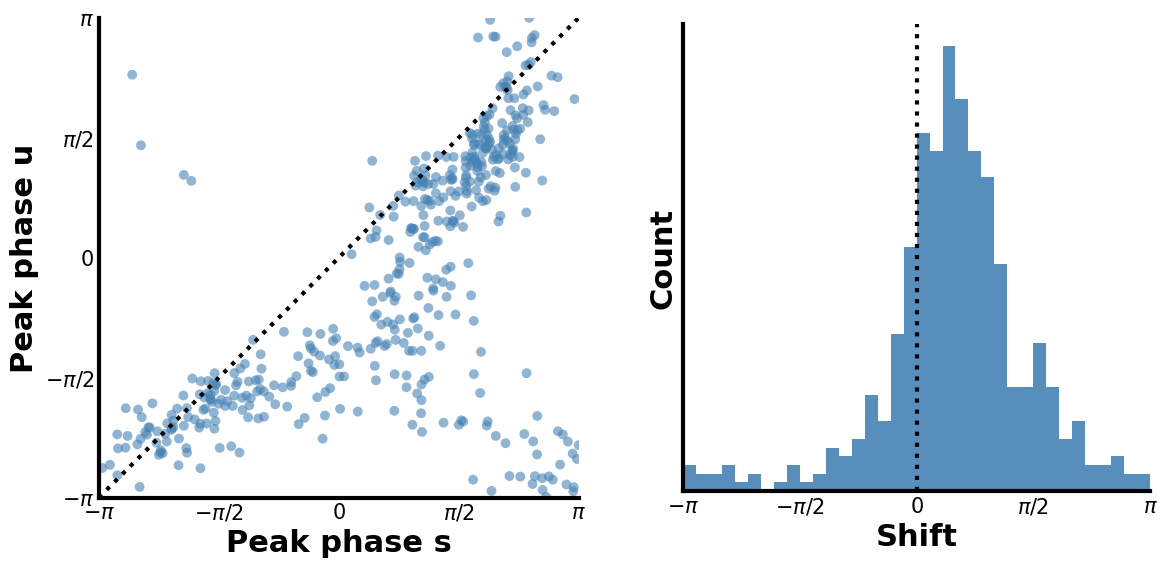

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def style_axes(ax, spine_lw=2.5):
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(spine_lw)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(axis='both', which='both', length=0)

LINE_W = 3
SPINE_W = 3
TITLE_FS = 18
ANN_FS = 10
TICK_FS = 15
LAB_FS  = 22 

ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
ticklabels = [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$']

for sam, s, u in zip(samples, nu_infos, nu_u_infos):
    idx_s, idx_u = s[10], u[10]
    angle_S = s[6][idx_s][idx_u]
    angle_U = u[6][idx_u]
    texts   = u[11]

    shifts = -(((angle_U - angle_S + np.pi) % (2*np.pi)) - np.pi)

    fig, (ax_sc, ax_hist) = plt.subplots(
        1, 2, figsize=(12, 6),
        gridspec_kw={'width_ratios': [1.15, 1.0]}
    )

    # --- left: scatter U vs S ---
    ax_sc.scatter(angle_S, angle_U, s=50, color='steelblue', alpha=0.6, edgecolors='none')
    ax_sc.plot([-np.pi, np.pi], [-np.pi, np.pi], 'k', linewidth=LINE_W, linestyle='dotted', label='identity')
    ax_sc.set_xlim(-np.pi, np.pi)
    ax_sc.set_ylim(-np.pi, np.pi)
    ax_sc.set_title(f"", fontsize=TITLE_FS, fontweight='bold')
    style_axes(ax_sc, spine_lw=SPINE_W)
    ax_sc.set_xticks(ticks); ax_sc.set_xticklabels(ticklabels, fontsize=TICK_FS)
    ax_sc.set_yticks(ticks); ax_sc.set_yticklabels(ticklabels, fontsize=TICK_FS)
    # >>> labels updated
    ax_sc.set_xlabel('Peak phase s', fontsize=LAB_FS, fontweight='bold')
    ax_sc.set_ylabel('Peak phase u', fontsize=LAB_FS, fontweight='bold')
    try:
        ax_sc.set_box_aspect(1)
    except AttributeError:
        ax_sc.set_aspect('equal', adjustable='box')

    # --- right: vertical histogram of signed shifts Δ ∈ [-π, π) ---
    bins = np.linspace(-np.pi, np.pi, 37)
    ax_hist.hist(shifts, bins=bins, color='steelblue', edgecolor='none', alpha=0.9)
    ax_hist.set_xlim(-np.pi, np.pi)
    ax_hist.set_title("", fontsize=TITLE_FS, fontweight='bold')
    ax_hist.axvline(0, color='k', linewidth=LINE_W, linestyle='dotted')
    style_axes(ax_hist, spine_lw=SPINE_W)
    ax_hist.set_xticks(ticks); ax_hist.set_xticklabels(ticklabels, fontsize=TICK_FS)
    # >>> labels updated
    ax_hist.set_xlabel('Shift', fontsize=LAB_FS, fontweight='bold')
    ax_hist.set_ylabel('Count', fontsize=LAB_FS, fontweight='bold')
    try:
        ax_hist.set_box_aspect(1)
    except AttributeError:
        ax_hist.set_aspect('equal', adjustable='box')

    fig.subplots_adjust(wspace=0.15, left=0.08, right=0.98, top=0.92, bottom=0.12)
    plt.show()


In [15]:
# Inputs
genes = s[11][idx_u]
amps  = u[7][idx_u]
xs_s  = s[3][idx_s][idx_u]
ys_s  = s[4][idx_s][idx_u]
xs_u  = u[3][idx_u]
ys_u  = u[4][idx_u]

# Assemble + filter once
df = pd.DataFrame({
    "Gene": genes,
    "amplitudes": amps,
    "xs_s": xs_s,
    "ys_s": ys_s,
    "xs_u": xs_u,
    "ys_u": ys_u,
})
df['Peaktime'] = df['Gene'].map(Phase_map)

df['phase_intron'] = np.mod(np.arctan2(df["xs_u"], df["ys_u"]), 2*np.pi)
df['phase_exon'] = np.mod(np.arctan2(df["xs_s"], df["ys_s"]), 2*np.pi)
df



,Gene,amplitudes,xs_s,ys_s,xs_u,ys_u,Peaktime,phase_intron,phase_exon
0,ac149090.1,0.397858,0.246664,-0.215794,0.224199,-0.328672,NaN,2.542956,2.289541
1,prim2,0.442273,0.286325,0.149560,0.193825,-0.397539,NaN,2.687944,1.089434
2,usp37,0.183976,0.167538,-0.120788,-0.010719,-0.183663,NaN,3.199890,2.195450
3,mcm6,0.476865,0.317302,-0.184551,-0.272794,-0.391131,G1,3.750604,2.097596
4,srgap2,0.108126,-0.114644,0.220168,-0.104758,0.026775,NaN,4.962616,5.803106
...,...,...,...,...,...,...,...,...,...
453,kif4,0.867259,-0.448245,0.687438,0.082981,0.863280,NaN,0.095829,5.705370
454,diaph2,0.240521,-0.103793,0.171930,0.205371,0.125192,NaN,1.023354,5.740056
455,cenpi,0.271547,-0.045173,0.469965,0.128526,0.239204,NaN,0.493047,6.187360
456,alg13,0.132327,0.117026,0.199874,0.131015,0.018588,NaN,1.429863,0.529688


In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Copy the datafram

# Define desired Peaktime order
peaktime_order = ['G1', 'G1/S', 'S', 'G2', 'G2/M', 'M']

# Soft HSV-based color map
hex_colors = ['#ffdf3e', '#ffa648', '#ea644e', '#bd265c', '#790063', '#15075c']
color_map = dict(zip(peaktime_order, hex_colors))

# Filter and select top 15 per Peaktime
top_n_per_group = 20
df = df[df['Peaktime'].isin(peaktime_order)]
df_grouped = (
    df.sort_values('amplitudes', ascending=False)
      .groupby('Peaktime', group_keys=False)
      .apply(lambda g: g.head(min(top_n_per_group, len(g))))
)



all


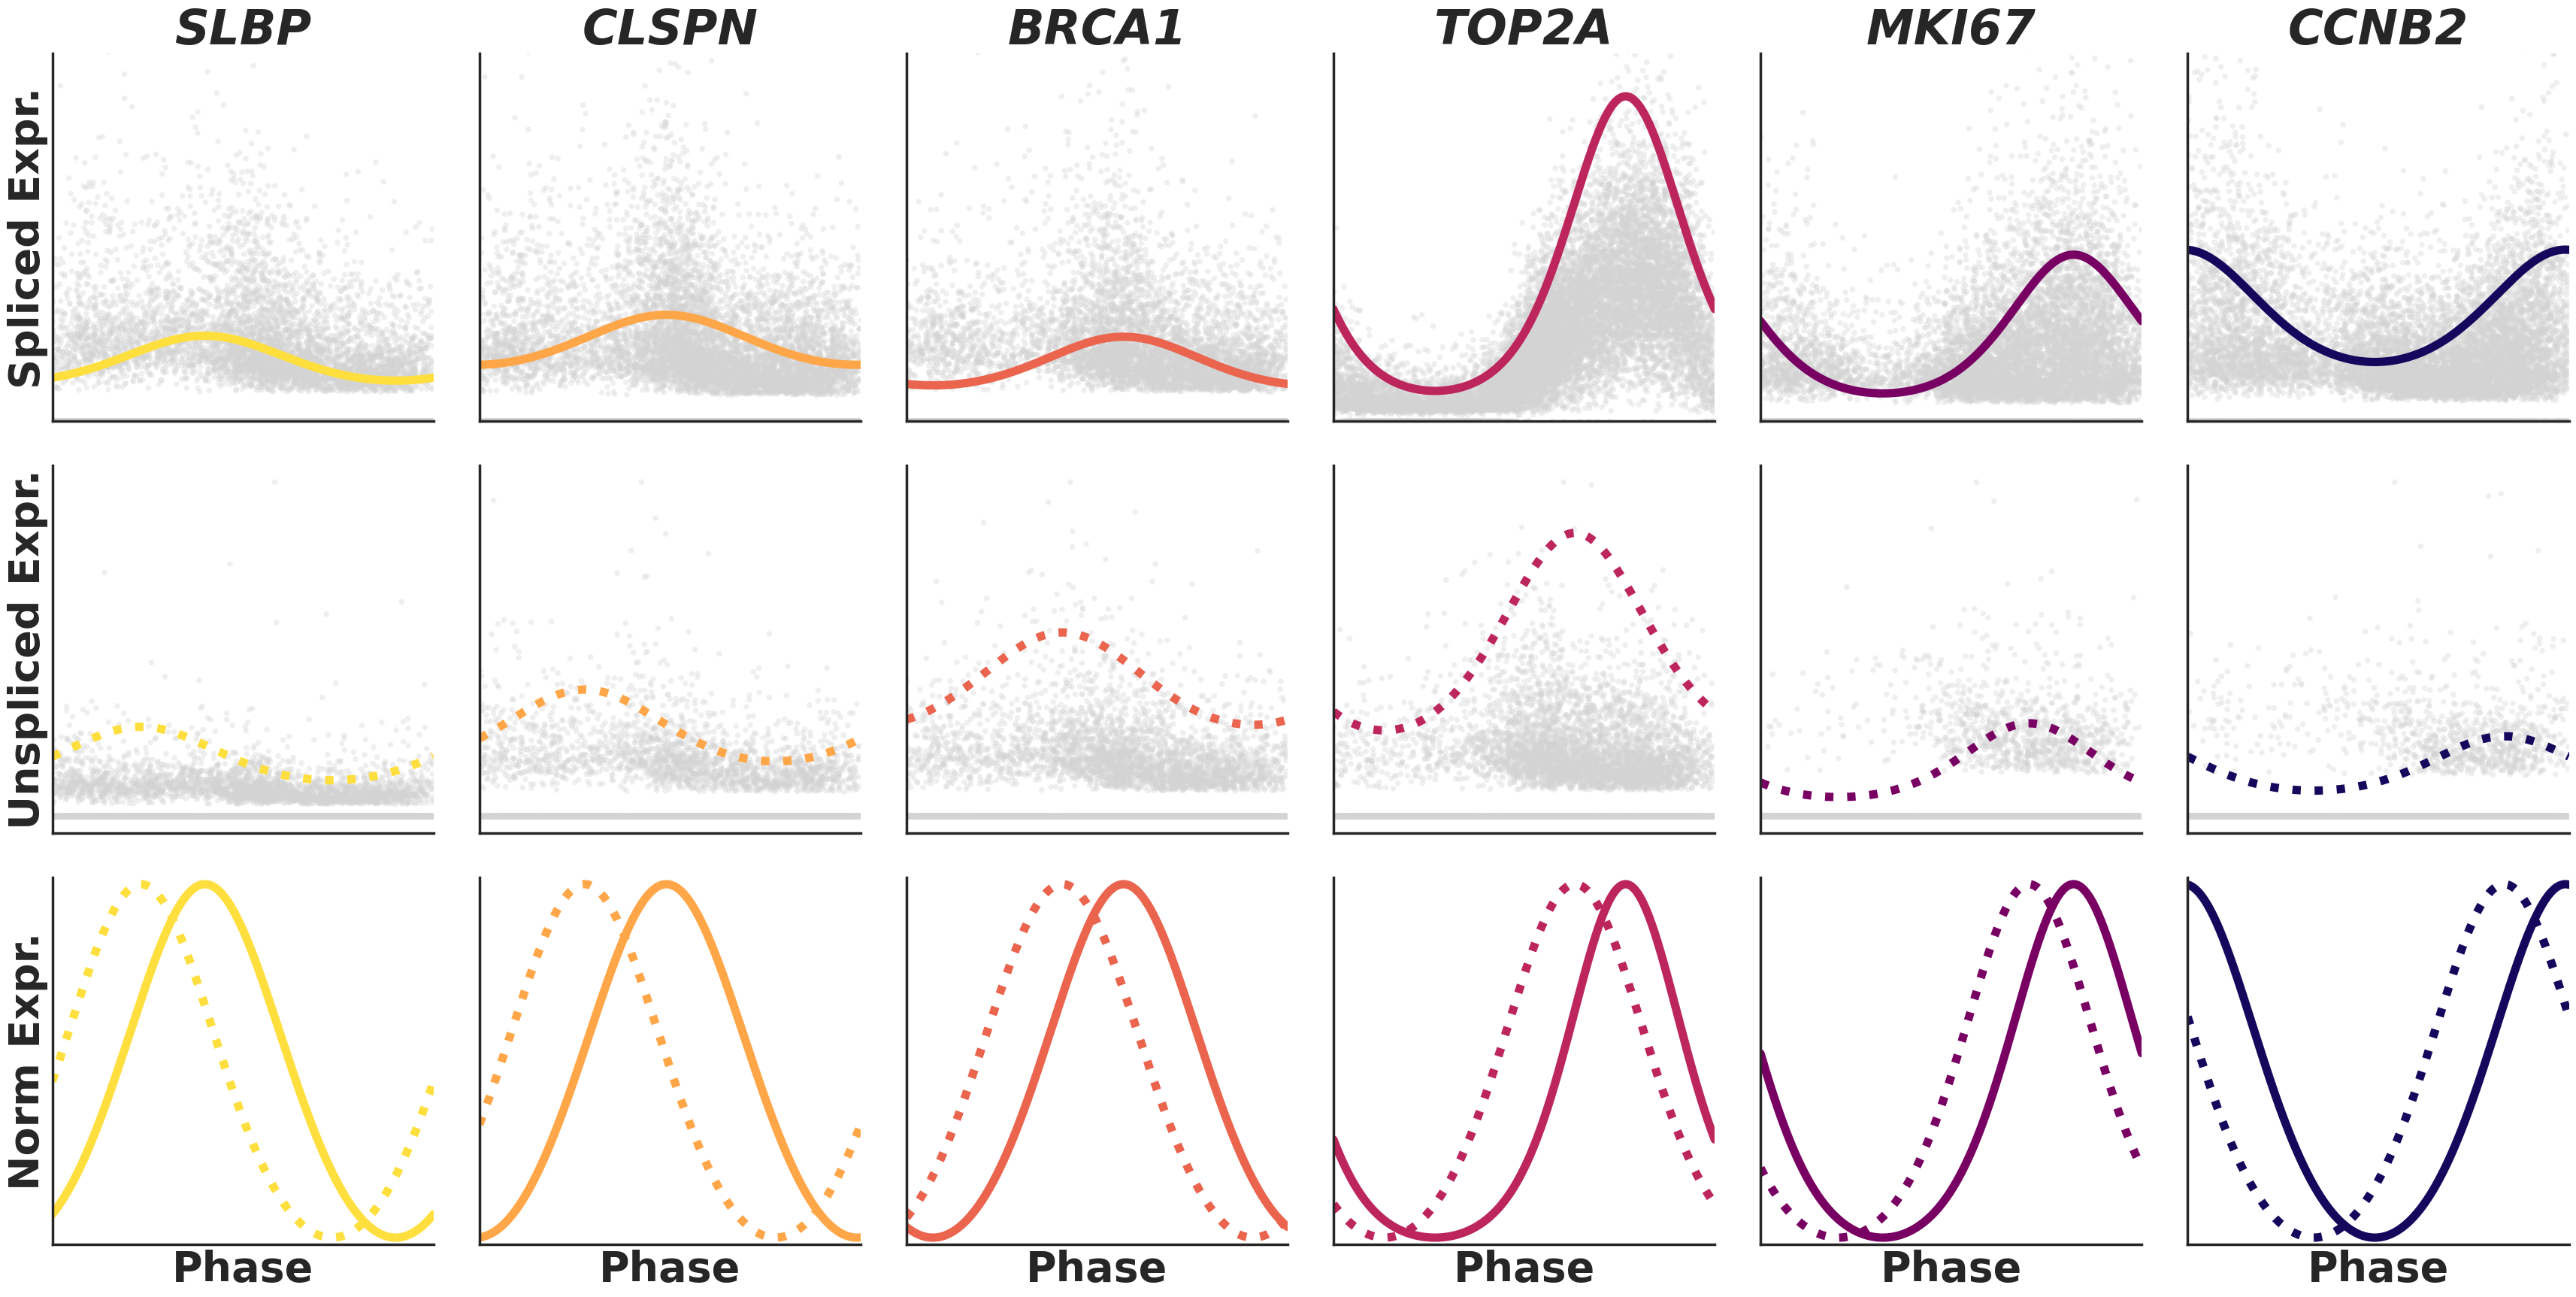

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import matplotlib.ticker as ticker

# --- global styling knobs ---
LINE_W = 8
FONT_SZ = 40
# ----------------------------

def wrap_to_pi(a):
    """Wrap angle(s) to [-pi, pi). Works with scalars or arrays."""
    return ((np.asarray(a) + np.pi) % (2*np.pi)) - np.pi

def set_phi_axis(ax):
    # >>> changed to [-pi, pi]
    ax.set_xlim(-np.pi, np.pi)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(axis='both', which='both', length=0)

def style_axes(ax, spine_lw=2.5):
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(spine_lw)

def minmax_scale(y):
    y = np.asarray(y, dtype=float)
    ymin, ymax = np.nanmin(y), np.nanmax(y)
    if ymax - ymin == 0:
        return np.zeros_like(y)
    return (y - ymin) / (ymax - ymin)

sns.set(font_scale=1, style='white', rc={'xtick.bottom': True, 'ytick.left': True})


gene_to_peaktime = {str(row['Gene']).upper(): row['Peaktime'] for _, row in df_grouped.iterrows()}
def gene_color(gene_upper):
    pt = gene_to_peaktime.get(gene_upper, None)
    return color_map.get(pt, 'grey')

to_plot = ['slbp', 'clspn', 'brca1', 'top2a', 'mki67', 'ccnb2']


phase_order = ['G1', 'G1/S', 'S', 'G2', 'G2/M', 'M']
phase_rank = {p: i for i, p in enumerate(phase_order)}
def _sort_key(g):
    pt = gene_to_peaktime.get(g.upper(), None)
    
    return (phase_rank.get(pt, 999), to_plot.index(g))
to_plot_sorted = sorted(to_plot, key=_sort_key)
# ----------------------------------------------

for sam, sample, u_sample in zip(samples, nu_infos, nu_u_infos):
    print(sam)

    idx_S, idx_U = sample[10], u_sample[10]
    fit_ElogS = sample[9][idx_S][idx_U][:, sample[13]]
    fit_ElogU = u_sample[9][idx_U]
    logN      = sample[14][sample[13]]
    data      = u_sample[12]

    # >>> wrap phases to [-pi, pi) 
    phis_raw = u_sample[0]
    phis = wrap_to_pi(phis_raw)

    order = np.argsort(phis)
    ph_sorted   = phis[order]
    logN_sorted = logN[order]

    ncols = len(to_plot_sorted)
    fig, ax = plt.subplots(3, ncols, figsize=(5*ncols+6, 18), squeeze=False)

    for j, g in enumerate(to_plot_sorted):
        g_up = g.upper()
        col = gene_color(g_up)

        gene_idx = np.where(data.var.index == g)[0]
        if gene_idx.size == 0:
            for r in range(3):
                ax[r, j].set_title(g, fontsize=FONT_SZ, fontweight='bold')
                set_phi_axis(ax[r, j]); style_axes(ax[r, j])
            continue
        gene_idx = gene_idx[0]

        sp_col = data.layers['spliced'][:, gene_idx]
        un_col = data.layers['unspliced'][:, gene_idx]
        yS = sp_col.A1 if hasattr(sp_col, 'A1') else np.asarray(sp_col).ravel()
        yU = un_col.A1 if hasattr(un_col, 'A1') else np.asarray(un_col).ravel()

        yS = (yS[order] / np.exp(logN_sorted)).astype(float, copy=False)
        yU = (yU[order] / np.exp(logN_sorted)).astype(float, copy=False)

        yy = np.asarray(fit_ElogS[gene_idx, :]).ravel()[order]
        yu = np.asarray(fit_ElogU[gene_idx, :]).ravel()[order]

        # Row 0
        ax[0, j].scatter(ph_sorted, yS, s=30, color='lightgrey', alpha=0.35, edgecolors='none')
        ax[0, j].plot(ph_sorted, 2*yy, color=col, linewidth=LINE_W)
        if yS.size and np.max(yS) > 0:
            ax[0, j].set_ylim(0, 0.8*np.max(yS))
        ax[0, j].set_title(str.upper(g), fontsize=46, fontweight='bold', fontstyle='italic')
        set_phi_axis(ax[0, j]); style_axes(ax[0, j])

        # Row 1
        ax[1, j].scatter(ph_sorted, yU, s=30, color='lightgrey', alpha=0.35, edgecolors='none')
        ax[1, j].plot(ph_sorted, 0.2*yu, color=col, linewidth=LINE_W, linestyle='dotted')
        set_phi_axis(ax[1, j]); style_axes(ax[1, j])

        # Row 2 (min–max scaled)
        yy_scaled = minmax_scale(yy)
        yu_scaled = minmax_scale(yu)
        ax[2, j].plot(ph_sorted, yy_scaled, color=col, linewidth=LINE_W)
        ax[2, j].plot(ph_sorted, yu_scaled, color=col, linewidth=LINE_W, linestyle='dotted')
        ax[2, j].set_ylim(-0.02, 1.02)
        set_phi_axis(ax[2, j]); style_axes(ax[2, j])

        # X label ONLY on bottom row
        ax[2, j].set_xlabel('Phase', fontsize=FONT_SZ, fontweight = 'bold')

    # y-axis labels only on first column
    ax[0, 0].set_ylabel('Spliced Expr.', fontsize=FONT_SZ, fontweight = 'bold')
    ax[1, 0].set_ylabel('Unspliced Expr.', fontsize=FONT_SZ, fontweight = 'bold')
    ax[2, 0].set_ylabel('Norm Expr.', fontsize=FONT_SZ, fontweight = 'bold')

    # Tighter spacing
    fig.subplots_adjust(wspace=0.12, hspace=0.12, left=0.06, right=0.99, top=0.96, bottom=0.08)
    
fig.savefig(
"FIGURES/Genes_profiles.png",
dpi=500,
bbox_inches="tight",
transparent=True
)

plt.show()


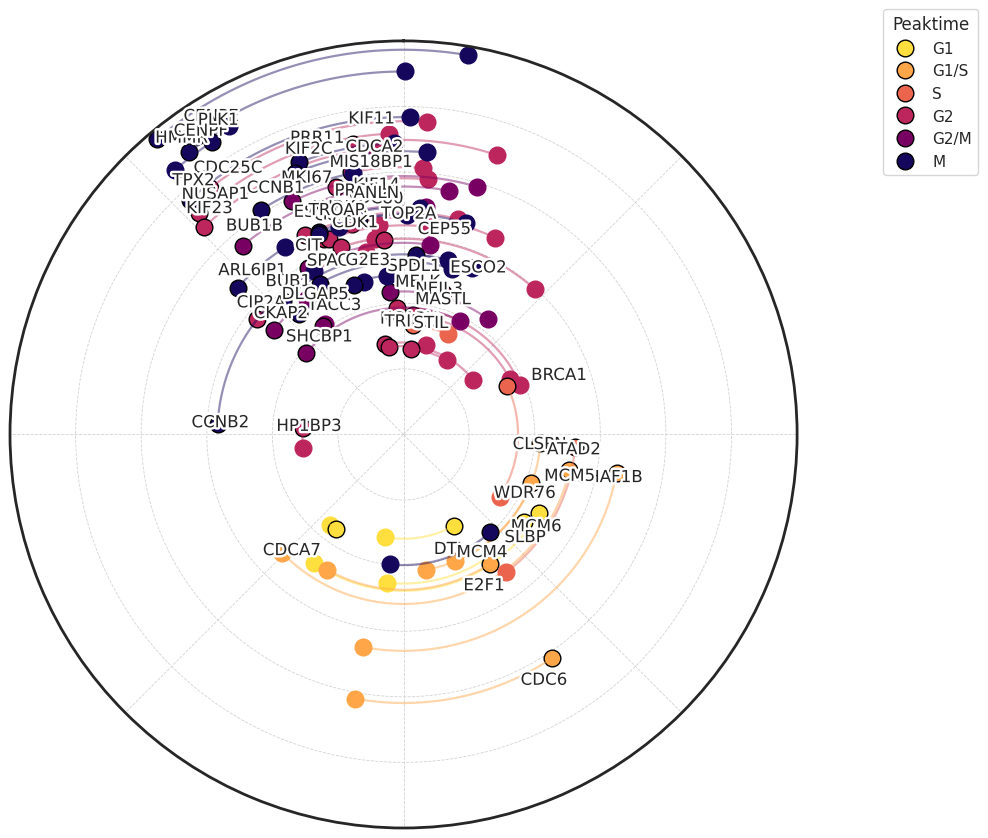

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patheffects as pe


ROTATE_BY_RAD = 0  

def wrap_to_pi(a):
    return ((np.asarray(a) + np.pi) % (2*np.pi)) - np.pi

def rotate_phase(a, phi):
    return wrap_to_pi(a + phi)

def to_polar_angle(a):
    return (a + 2*np.pi) % (2*np.pi)

# Layout + styling knobs
MARKER_SZ_IN = 12     # intron marker size
MARKER_SZ_EX = 12     # exon marker size
LABEL_FS     = 12     # gene label font size
LABEL_WT     = 'normal'
LABEL_RADIAL_OFFSET = 0.08  # radial offset from marker
OUTLINE = [pe.withStroke(linewidth=3.5, foreground="white")]  # text outline

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(10, 10))

# Set fixed outer radius to control arc and grid scale
outer_radius = 1.2
ax.set_ylim(0, outer_radius)

for _, row in df_grouped.iterrows():
    # --- rotate phases exactly like in the gene profiles ---
    theta_intron_raw = row['phase_intron']
    theta_exon_raw   = row['phase_exon']

    theta_intron = rotate_phase(theta_intron_raw, ROTATE_BY_RAD)   # [-pi, pi)
    theta_exon   = rotate_phase(theta_exon_raw,   ROTATE_BY_RAD)   # [-pi, pi)

    # for polar plotting, map to [0, 2pi)
    th_i = to_polar_angle(theta_intron)
    th_e = to_polar_angle(theta_exon)

    r_exon = row['amplitudes']
    gene   = row['Gene'].upper()
    color  = color_map.get(row['Peaktime'], 'grey')

    # markers
    ax.plot(th_i, r_exon, 'o', color=color, alpha=1, markersize=MARKER_SZ_IN)
    ax.plot(th_e, r_exon, 'o', color=color, markeredgecolor='black', markeredgewidth=1.0,
            alpha=1, markersize=MARKER_SZ_EX)

    # --- shortest arc on the ROTATED angles ---
    dtheta = (theta_exon - theta_intron + np.pi) % (2*np.pi) - np.pi  # [-pi, pi)
    t = np.linspace(0.0, 1.0, 100)
    arc_theta_wrapped = wrap_to_pi(theta_intron + t * dtheta)
    arc_theta_polar   = to_polar_angle(arc_theta_wrapped)
    arc_r = np.full_like(arc_theta_polar, r_exon)
    ax.plot(arc_theta_polar, arc_r, color=color, alpha=0.45, linewidth=1.6)

    # --- gene annotation near exon point ---
    r_label = min(r_exon + LABEL_RADIAL_OFFSET, outer_radius - 0.02)


    ang = th_e % (2*np.pi)
    if 0 <= ang < np.pi/2 or (3*np.pi/2) <= ang < 2*np.pi:
        ha = 'left'
    else:
        ha = 'right'
    va = 'center'


    ax.text(th_e, r_label, gene, fontsize=LABEL_FS, fontweight=LABEL_WT,
            ha=ha, va=va, rotation=0, path_effects=OUTLINE)

# Legend 
handles = [plt.Line2D([0], [0], marker='o', color='w', label=pt,
                      markerfacecolor=color_map[pt], markeredgecolor='black', markersize=12)
           for pt in peaktime_order]
ax.legend(handles=handles, bbox_to_anchor=(1.1, 1.05), title="Peaktime", loc='upper left')

# Polar settings & aesthetics
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_xticks([])
ax.set_yticklabels([])
ax.tick_params(axis='y', length=0)
ax.grid(True, which='both', color='lightgrey', linestyle='--', linewidth=0.6)
ax.spines['polar'].set_linewidth(2)

for angle in np.linspace(0, 2*np.pi, 8, endpoint=False):
    ax.plot([angle, angle], [0, outer_radius], color='lightgrey', linestyle='--', linewidth=0.6, zorder=0)

plt.tight_layout()
fig.savefig(
"FIGURES/Gene_polarplot.png",
dpi=500,
bbox_inches="tight",
transparent=True
)

plt.show()
